# Profiling a ligand set

Load the bundled DUD-E EGFR ligands, run the RDKit BaseFeatures SMARTS set over every structure, and read the count table. The subset is 542 unique actives plus 2,500 official property-matched decoys; see `data/README.md`.

In [1]:
from pathlib import Path
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw

from pharmprof.data import load_egfr
from pharmprof.patterns import builtin_patterns
from pharmprof.profiler import profile, family_counts
from pharmprof.stats import pattern_summary
from pharmprof.io import MolRecord

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)

data = load_egfr(subset=True)
print(data.shape)
print(data["label"].value_counts().to_dict())
data.head()

/workspace/venvs/pharmprof/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(3042, 6)
{0: 2500, 1: 542}


,smiles,mol_id,label,chembl_id,target,source
0,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,101343,1,CHEMBL63786,egfr,DUD-E
1,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,81022,1,CHEMBL53711,egfr,DUD-E
2,Brc1cccc(Nc2ncnc3cc4[nH]cnc4cc23)c1,101370,1,CHEMBL66031,egfr,DUD-E
3,Cn1cnc2cc3ncnc(Nc4cccc(Br)c4)c3cc21,290482,1,CHEMBL176582,egfr,DUD-E
4,CCOc1cc2ncc(C#N)c(Nc3ccc(OCc4ccccn4)c(Cl)c3)c2...,299120,1,CHEMBL180022,egfr,DUD-E


Each row is one ligand. `label=1` is a DUD-E EGFR active, `label=0` a property-matched decoy. Build RDKit molecules and run the 27 BaseFeatures patterns (counts = unique substructure matches).

In [2]:
recs = [
    MolRecord(mol_id=str(r.mol_id), smiles=r.smiles, mol=Chem.MolFromSmiles(r.smiles), label=int(r.label))
    for r in data.itertuples()
]
print("invalid SMILES:", sum(r.mol is None for r in recs))

patterns = builtin_patterns("basefeatures")
print(f"{len(patterns)} patterns, families: {sorted({p.family for p in patterns})}")

table = profile(recs, patterns, mode="count", n_jobs=4, progress=True)
table["label"] = [r.label for r in recs]
table.head()

invalid SMILES: 0
27 patterns, families: ['Acceptor', 'Aromatic', 'Donor', 'Hydrophobe', 'LumpedHydrophobe', 'NegIonizable', 'PosIonizable', 'ZnBinder']


profile: 100%|██████████| 1/1 [00:02<00:00,  2.43s/chunk]


,mol_id,smiles,valid,label,n_heavy,basefeatures.Donor.SingleAtomDonor,...,basefeatures.LumpedHydrophobe.RH6_6,basefeatures.LumpedHydrophobe.RH5_5,basefeatures.LumpedHydrophobe.RH4_4,basefeatures.LumpedHydrophobe.RH3_3,basefeatures.LumpedHydrophobe.tButyl,basefeatures.LumpedHydrophobe.iPropyl
0,101343,Brc1cccc(Nc2ncnc3cc4ccccc4cc23)c1,True,1,22,1.0,...,3.0,0.0,0.0,0.0,0.0,0.0
1,81022,CN(C)c1cc2c(Nc3cccc(Br)c3)ncnc2cn1,True,1,21,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0
2,101370,Brc1cccc(Nc2ncnc3cc4[nH]cnc4cc23)c1,True,1,21,3.0,...,2.0,0.0,0.0,0.0,0.0,0.0
3,290482,Cn1cnc2cc3ncnc(Nc4cccc(Br)c4)c3cc21,True,1,22,1.0,...,2.0,0.0,0.0,0.0,0.0,0.0
4,299120,CCOc1cc2ncc(C#N)c(Nc3ccc(OCc4ccccn4)c(Cl)c3)c2...,True,1,40,3.0,...,2.0,0.0,0.0,0.0,0.0,0.0


Hit rates and count distributions, all patterns:

In [3]:
summary = pattern_summary(table, patterns)
summary.sort_values("hit_rate", ascending=False)[
    ["pattern_id", "family", "hit_count", "hit_rate", "mean", "max"]
]

,pattern_id,family,hit_count,hit_rate,mean,max
1,basefeatures.Acceptor.SingleAtomAcceptor,Acceptor,3006,0.988166,3.651216,11.0
18,basefeatures.Hydrophobe.ThreeWayAttach,Hydrophobe,2989,0.982577,3.483563,11.0
0,basefeatures.Donor.SingleAtomDonor,Donor,2962,0.973702,2.327416,6.0
15,basefeatures.Aromatic.Arom6,Aromatic,2894,0.951348,2.043064,5.0
21,basefeatures.LumpedHydrophobe.RH6_6,LumpedHydrophobe,2863,0.941157,1.715319,6.0
14,basefeatures.Aromatic.Arom5,Aromatic,1577,0.518409,0.665352,3.0
19,basefeatures.Hydrophobe.ChainTwoWayAttach,Hydrophobe,1449,0.476331,0.782380,14.0
4,basefeatures.PosIonizable.PosN,PosIonizable,971,0.319198,0.332676,2.0
22,basefeatures.LumpedHydrophobe.RH5_5,LumpedHydrophobe,467,0.153517,0.170611,3.0
3,basefeatures.PosIonizable.BasicGroup,PosIonizable,391,0.128534,0.145957,3.0


Family-level sums (pattern matches can overlap, so these are not unique-atom counts):

In [4]:
fam = family_counts(table, patterns, how="sum")
fam = fam.join(table[["label"]])
fam.groupby("label").mean(numeric_only=True).T.rename(columns={0: "decoys", 1: "actives"})

label,decoys,actives
Donor,2.2752,2.568266
Acceptor,3.5024,4.337638
NegIonizable,0.0180,0.007380
PosIonizable,0.5168,0.658672
ZnBinder,0.0240,0.007380
Aromatic,2.5112,3.621771
Hydrophobe,4.3380,3.933579
LumpedHydrophobe,2.1180,2.035055


A quick look at gefitinib (CHEMBL939), which is in the set, and the patterns that fire on it.

CHEMBL939 hits:
  basefeatures.Donor.SingleAtomDonor             count=2
  basefeatures.Acceptor.SingleAtomAcceptor       count=6
  basefeatures.PosIonizable.BasicGroup           count=1
  basefeatures.Aromatic.Arom6                    count=3
  basefeatures.Hydrophobe.ThreeWayAttach         count=2
  basefeatures.Hydrophobe.ChainTwoWayAttach      count=1
  basefeatures.LumpedHydrophobe.RH6_6            count=2


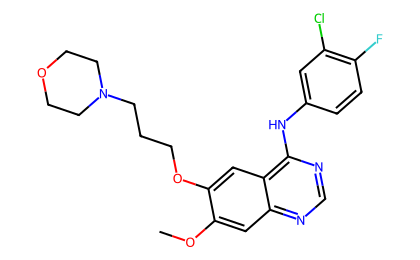

In [5]:
# DUD-E id 88232 is gefitinib (CHEMBL939)
row = table.loc[table["mol_id"].astype(str) == "88232"].iloc[0]
fired = [p.pattern_id for p in patterns if row[p.pattern_id] > 0]
print("CHEMBL939 hits:")
for pid in fired:
    print(f"  {pid:45s}  count={int(row[pid])}")
mol = Chem.MolFromSmiles(row.smiles)
Draw.MolToImage(mol, size=(420, 260))